In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

pd.set_option('display.max_columns', None)

In [ ]:
df=pd.read_csv("bank_notes.csv")

In [ ]:
df.head()

,variance,skewness,curtosis,entropy,Target
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [ ]:
df.tail()

,variance,skewness,curtosis,entropy,Target
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1
1371,-2.54190,-0.65804,2.6842,1.19520,1


In [ ]:
df.columns

Index(['variance', 'skewness', 'curtosis', 'entropy', 'Target'], dtype='object')

In [ ]:
df.shape

(1372, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   Target    1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [ ]:
df.describe()

,variance,skewness,curtosis,entropy,Target
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [ ]:
df.isnull().sum()

,0
variance,0
skewness,0
curtosis,0
entropy,0
Target,0


In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
1367,False
1368,False
1369,False
1370,False


## Visualization

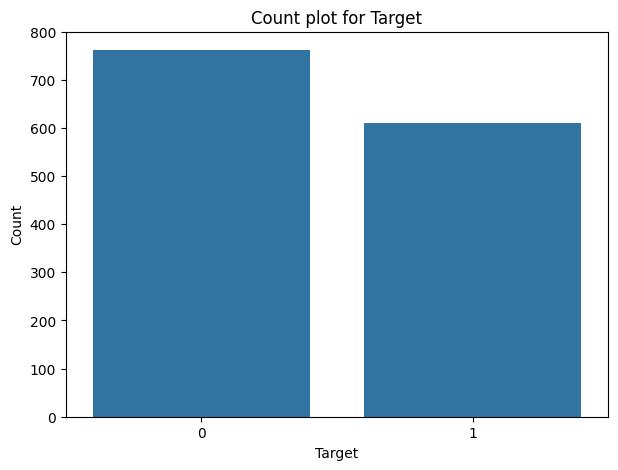

In [ ]:
#bar plot
plt.figure(figsize=(7,5))
sns.countplot(x="Target", data=df)

plt.title("Count plot for Target")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

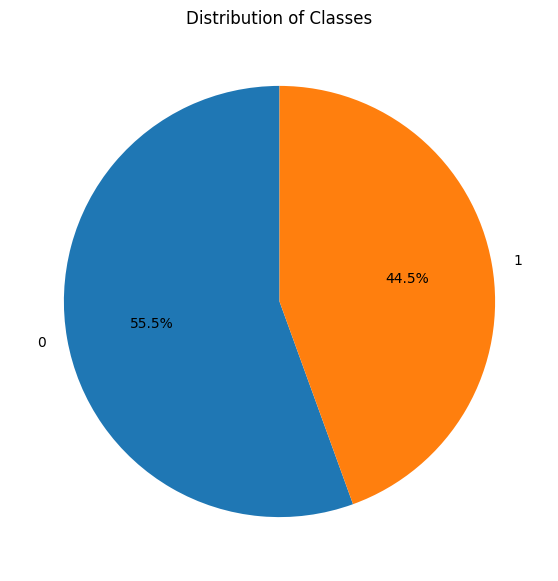

In [ ]:
#pie chart
class_counts=df["Target"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(class_counts, labels=class_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Distribution of Classes")
plt.show()

In [ ]:
numerical_features=df.select_dtypes(include=np.number).columns
print("Numerical features")
print(numerical_features.to_list())

Numerical features
['variance', 'skewness', 'curtosis', 'entropy', 'Target']


### Histograms

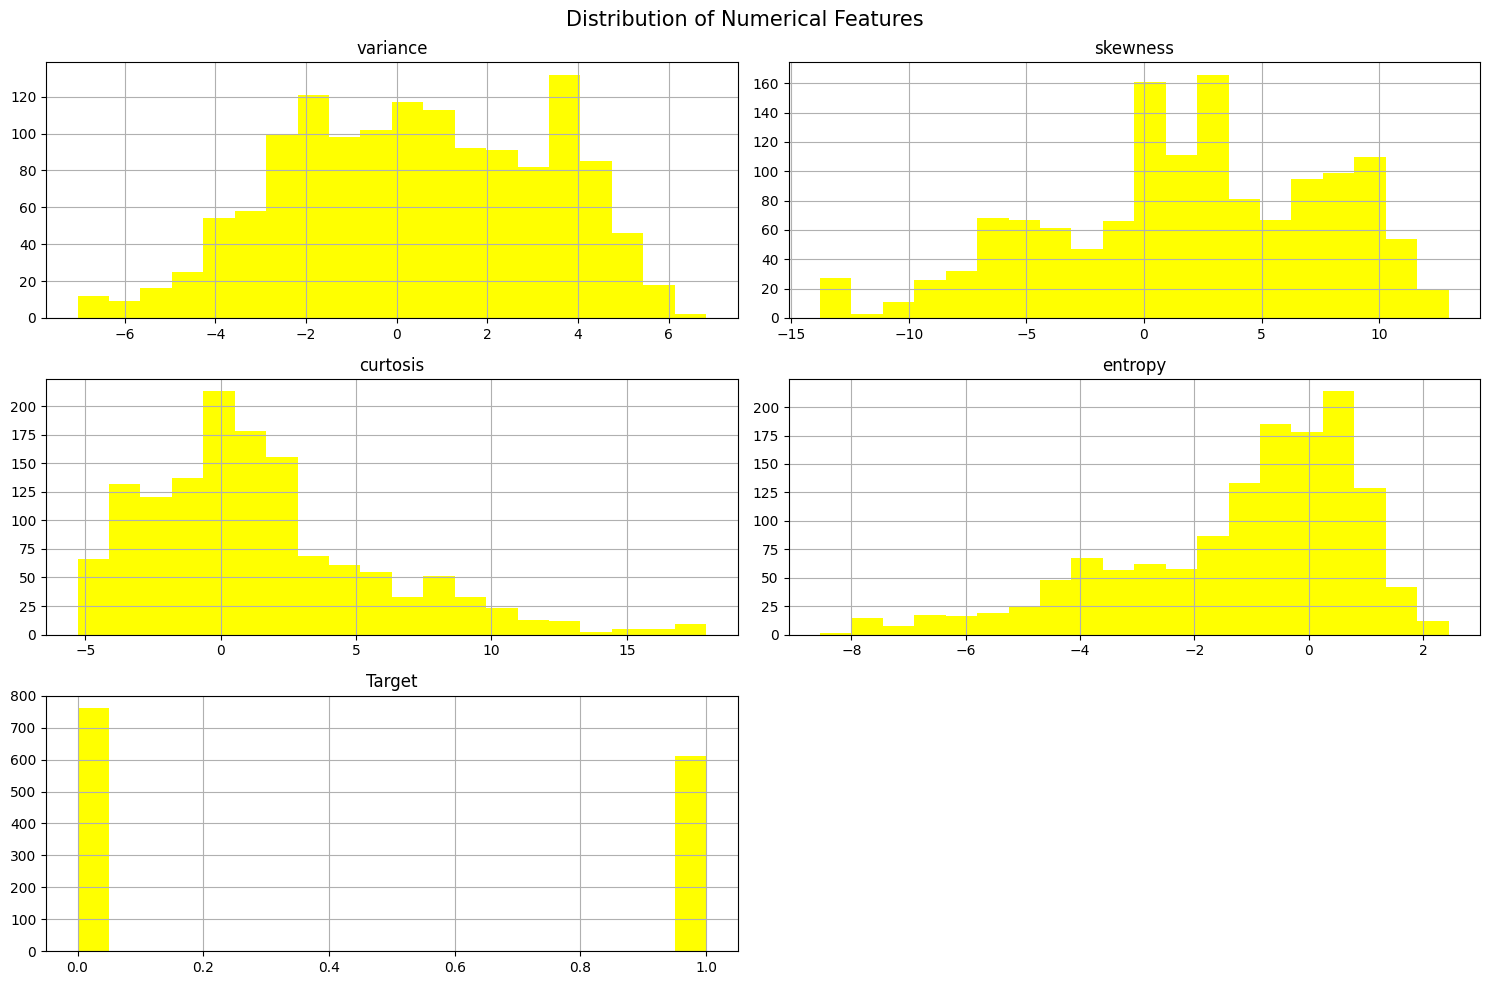

In [ ]:
df[numerical_features].hist(figsize=(15,10),bins=20,color='yellow')
plt.suptitle("Distribution of Numerical Features",fontsize=15)
plt.tight_layout()
plt.show()

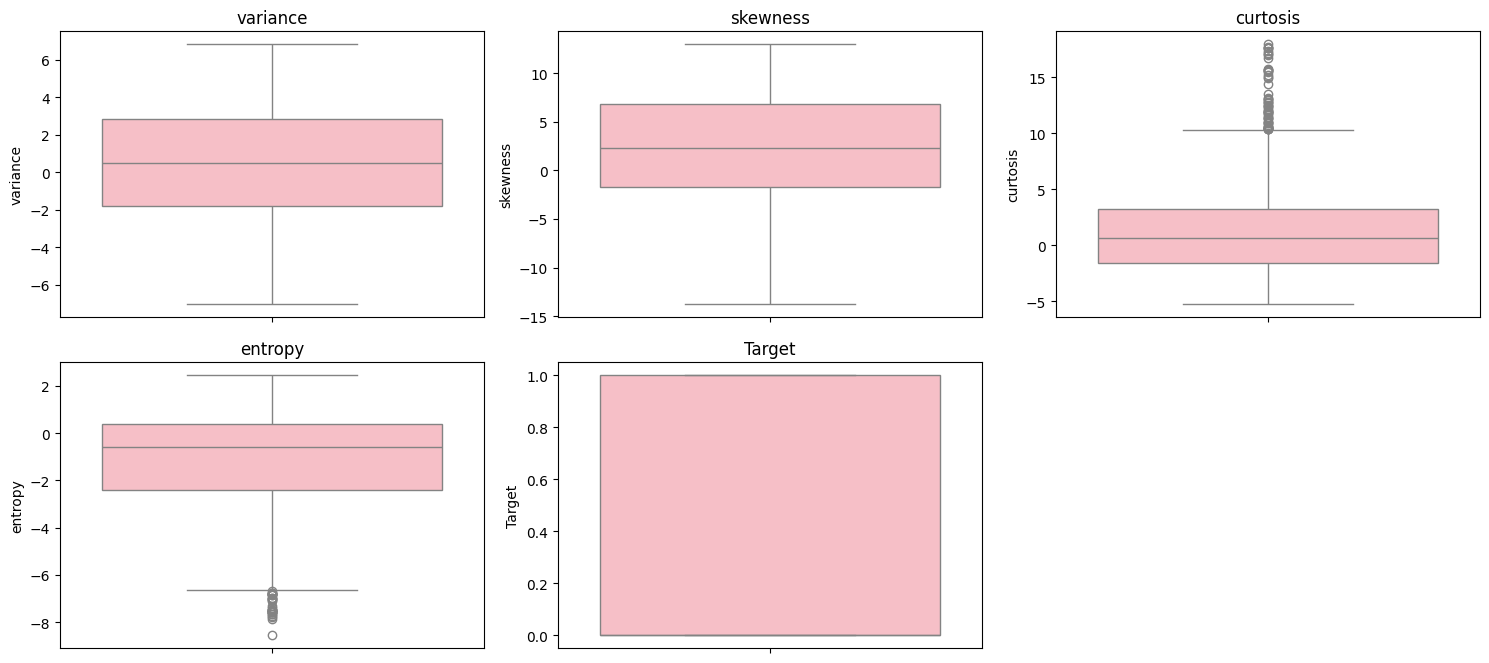

In [ ]:
# boxplot
plt.figure(figsize=(15,10))
for i, column in enumerate(numerical_features,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[column],color='lightpink')
    plt.title(column)
plt.tight_layout()
plt.show()

### Histograms with KDE function

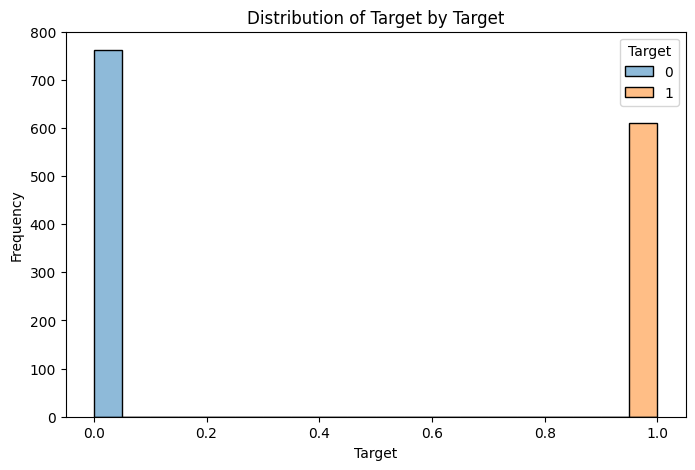

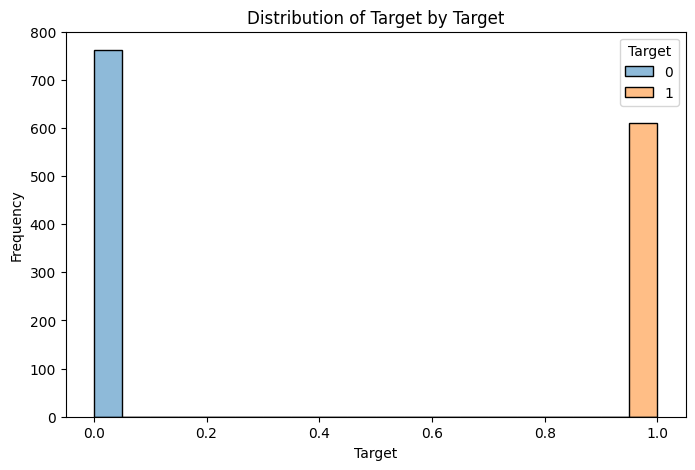

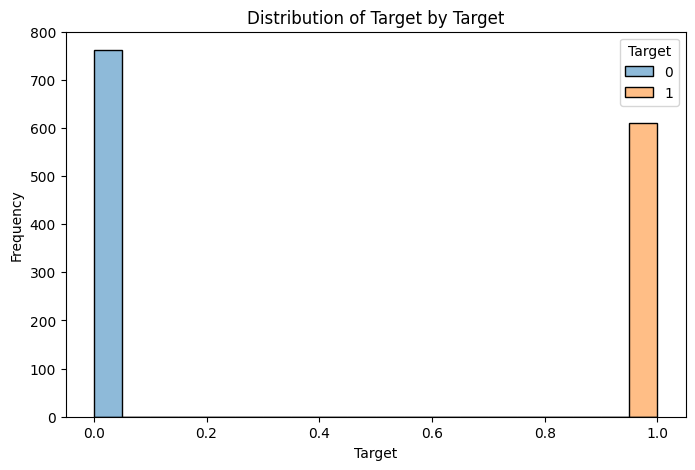

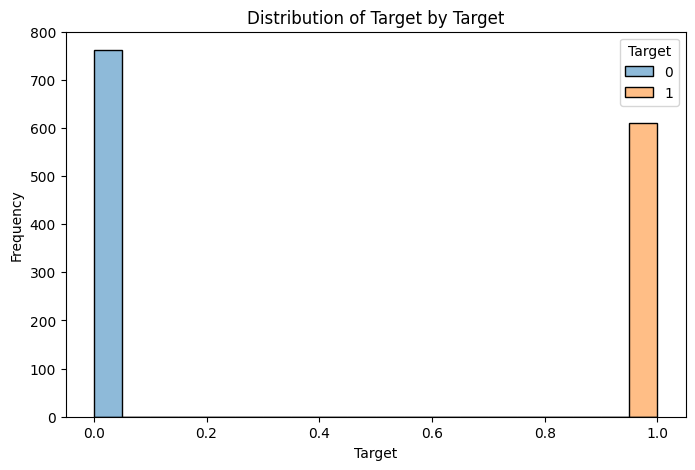

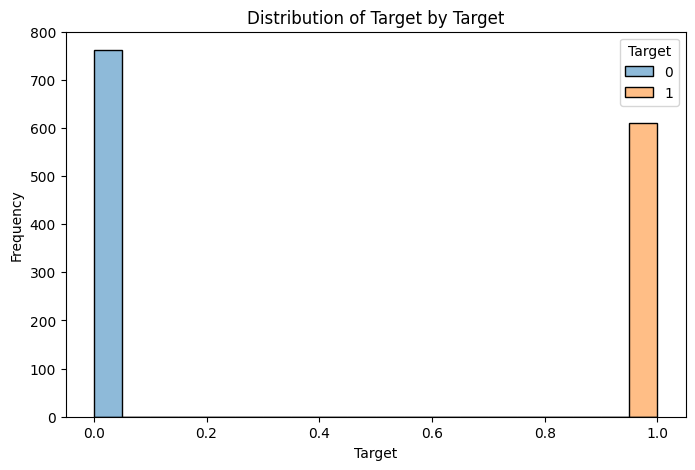

In [ ]:
for columns in numerical_features:
    plt.figure(figsize=(8,5))
    sns.histplot(data=df,x=column,hue='Target',kde=True,bins=20)
    plt.title(f"Distribution of {column} by Target")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()


### Correlation matrix

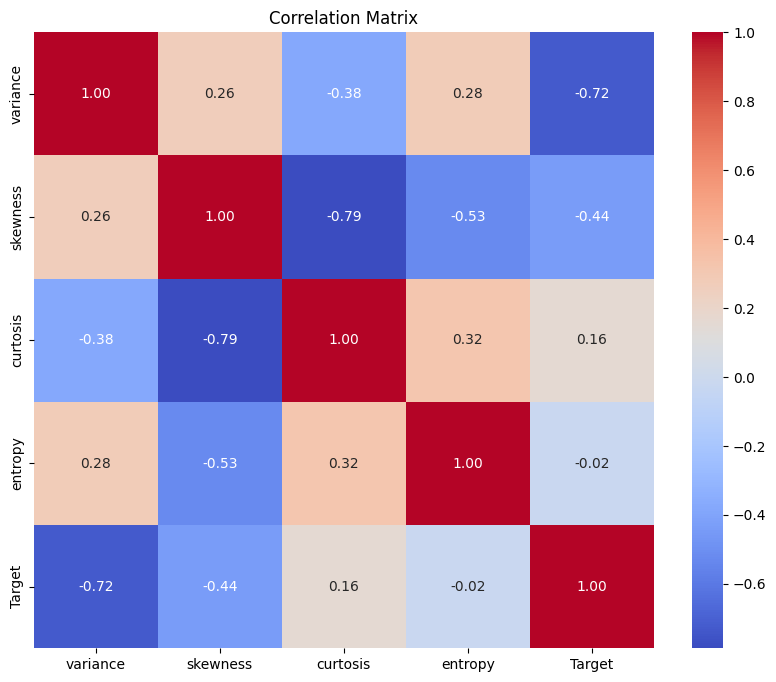

In [ ]:
correlation_matrix=df.corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### Scatter plot

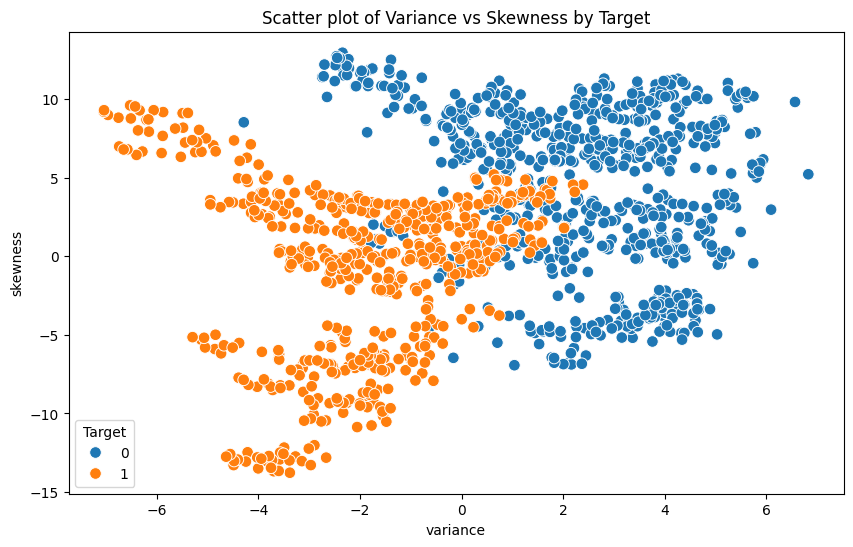

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x="variance", y="skewness", hue="Target", s=70)
plt.title("Scatter plot of Variance vs Skewness by Target")
plt.show()

### Algorithm

In [ ]:
X= df.drop("Target", axis=1)
y=df["Target"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1372, 4)
Shape of y: (1372,)


In [ ]:
X_train, X_test, y_train, y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples", X_train.shape[0])
print("Testing samples", X_test.shape[0])

Training samples 1097
Testing samples 275


In [ ]:
GaussianNB()

GaussianNB()

In [ ]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [ ]:
y_pred=gnb.predict(X_test)
print("Predicted labels:")
print(y_pred)

Predicted labels:
[0 1 0 1 1 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 0 1 1 0 0 1 1 1 0 0 0 0 0 1 1 1 0
 1 0 0 1 0 1 0 1 1 0 0 0 1 0 1 1 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0
 0 1 1 0 0 1 1 0 1 1 0 1 1 1 1 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 1
 1 0 0 1 0 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0 0 1 1 1 0 0 1 1 1 1 1 0 1 0 1 0 0
 0 0 0 0 1 1 0 0 1 0 1 0 1 0 1 0 0 0 0 1 0 0 1 1 1 0 1 0 1 0 0 1 0 0 1 0 0
 1 1 1 1 1 0 1 0 1 0 1 1 1 1 1 0 0 1 1 1 0 1 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1
 1 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 0
 0 1 0 1 1 0 0 1 0 0 1 0 0 0 0 0]


In [ ]:
comparison=pd.DataFrame({"Actual":y_test.values, "Predicted":y_pred})
print(comparison.head(20))

    Actual  Predicted
0        0          0
1        1          1
2        0          0
3        1          1
4        1          1
5        1          0
6        0          0
7        0          0
8        0          1
9        1          1
10       0          0
11       1          1
12       0          0
13       0          0
14       0          0
15       0          0
16       1          1
17       1          1
18       1          1
19       0          0


In [ ]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8581818181818182


In [ ]:
precision=precision_score(y_test,y_pred)
print("Precision:", precision)

Precision: 0.8487394957983193


In [ ]:
recall=recall_score(y_test,y_pred)
print("Recall:", recall)

Recall: 0.8278688524590164


In [ ]:
f1=f1_score(y_test,y_pred)
print("F1 Score:", f1)

F1 Score: 0.8381742738589212


In [ ]:
print("Model performance:")

print(f"Accuracy: {accuracy*100:.4f}%")
print(f"Precision: {precision*100:.4f}%")
print(f"Recall: {recall*100:.4f}%")
print(f"F1 Score: {f1*100:.4f}%")

Model performance:
Accuracy: 85.8182%
Precision: 84.8739%
Recall: 82.7869%
F1 Score: 83.8174%


In [ ]:
print("classification_report:\n")
print(classification_report(y_test,y_pred))

classification_report:

              precision    recall  f1-score   support

           0       0.87      0.88      0.87       153
           1       0.85      0.83      0.84       122

    accuracy                           0.86       275
   macro avg       0.86      0.86      0.86       275
weighted avg       0.86      0.86      0.86       275



In [ ]:
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[135  18]
 [ 21 101]]


In [ ]:
y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)

train_accuracy=accuracy_score(y_train,y_train_pred)
test_accuracy=accuracy_score(y_test,y_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.8395624430264357
Testing Accuracy: 0.8581818181818182
